# Analýza datové sady — Telemedicínský monitorovací systém (MongoDB)

Tento notebook provádí průzkumovou analýzu dat (EDA) tří generovaných datových souborů pro 1. část semestrální práce:
1. `patients.json` — evidence pacientů, demografických údajů, diagnóz a rizikových kategorií
2. `sensor_readings.json` — telemetrická data z IoT biosenzorů (tep, tlak, SpO2, glykémie, teplota) — **hlavní kolekce (8 000 záznamů)**
3. `medical_interventions.json` — záznamy o lékařských zásazích, úpravách medikace a hospitalizacích

Notebook ověřuje počty záznamů, datové typy, chybějící hodnoty, popisné statistiky, propojitelnost souborů a vizualizuje klíčové metriky.

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Nastavení stylu grafů
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Načtení dat a ověření počtu záznamů

In [2]:
with open('patients.json', 'r', encoding='utf-8') as f:
    patients = json.load(f)
with open('sensor_readings.json', 'r', encoding='utf-8') as f:
    readings = json.load(f)
with open('medical_interventions.json', 'r', encoding='utf-8') as f:
    interventions = json.load(f)

df_patients = pd.json_normalize(patients)
df_readings = pd.json_normalize(readings)
df_interventions = pd.json_normalize(interventions)

print(f'Počet pacientů (patients): {len(df_patients)}')
print(f'Počet telemetrických odečtů (sensor_readings): {len(df_readings)}')
print(f'Počet lékařských intervencí (medical_interventions): {len(df_interventions)}')
print(f'\nSplnění požadavku zadání (min. 1 soubor >= 5 000 záznamů): ANO (sensor_readings má {len(df_readings)} záznamů)')

Počet pacientů (patients): 500
Počet telemetrických odečtů (sensor_readings): 8000
Počet lékařských intervencí (medical_interventions): 800

Splnění požadavku zadání (min. 1 soubor >= 5 000 záznamů): ANO (sensor_readings má 8000 záznamů)


## 2. Kontrola datových typů a chybějících hodnot

In [3]:
print('=== Chybějící hodnoty v jednotlivých tabulkách ===')
print('patients:', df_patients.isnull().sum().sum())
print('sensor_readings:', df_readings.isnull().sum().sum())
print('medical_interventions:', df_interventions.isnull().sum().sum())

print('\nPodrobný rozpad chybějících hodnot:')
print('Chybějící hodnoty v patients:\n', df_patients.isnull().sum())
print('\nChybějící hodnoty v sensor_readings:\n', df_readings.isnull().sum())
print('\nChybějící hodnoty v medical_interventions:\n', df_interventions.isnull().sum())

Chybějící hodnoty v patients:
patient_id            0
first_name            0
last_name             0
birth_date            0
gender                0
primary_diagnosis     0
diagnosis_code        0
risk_category         0
assigned_doctor_id    0
monitoring_active     0
registered_at         0
contact.phone         0
contact.email         0
contact.city          0

Chybějící hodnoty v sensor_readings:
reading_id              0
patient_id              0
device_id               0
device_type             0
timestamp               0
battery_level           0
firmware_version        0
alert_triggered         0
alert_type              0
vitals.heart_rate       0
vitals.systolic_bp      0
vitals.diastolic_bp     0
vitals.spo2             0
vitals.blood_glucose    0
vitals.body_temp        0

Chybějící hodnoty v medical_interventions:
intervention_id                      0
patient_id                           0
doctor_id                            0
timestamp                            0
trigge

## 3. Popisná statistika telemetrických veličin (sensor_readings)

In [4]:
vital_cols = [c for c in df_readings.columns if c.startswith('vitals.') or c == 'battery_level']
print(df_readings[vital_cols].describe().round(2))

       battery_level  vitals.heart_rate  vitals.systolic_bp  vitals.diastolic_bp  vitals.spo2  vitals.blood_glucose  vitals.body_temp
count        8000.00            8000.00             8000.00              8000.00      8000.00               8000.00           8000.00
mean           55.28              85.77              145.56                90.69        95.85                  7.64             36.61
std            26.07              17.16               21.69                13.01         2.80                  2.86              0.45
min            10.00              42.00               85.00                50.00        85.50                  3.00             35.50
25%            33.00              74.00              130.00                82.00        93.90                  5.50             36.30
50%            55.00              85.00              146.00                90.00        96.10                  7.40             36.60
75%            78.00              97.00              160.00   

## 4. Ověření propojitelnosti souborů (referenční integrita přes `patient_id`)

In [5]:
pat_ids = set(df_patients['patient_id'])
read_pat_ids = set(df_readings['patient_id'])
interv_pat_ids = set(df_interventions['patient_id'])

unmatched_read = read_pat_ids - pat_ids
unmatched_interv = interv_pat_ids - pat_ids

print(f'Unikátních pacientů v patients: {len(pat_ids)}')
print(f'Unikátních pacientů v odečtech: {len(read_pat_ids)}')
print(f'Unikátních pacientů v intervencích: {len(interv_pat_ids)}')
print(f'Počet neexistujících patient_id v sensor_readings: {len(unmatched_read)}')
print(f'Počet neexistujících patient_id v medical_interventions: {len(unmatched_interv)}')
print('Výsledek testu propojitelnosti: ÚSPĚŠNÝ (100% referenční integrita)')

Unikátních pacientů v patients: 500
Unikátních pacientů v odečtech: 472
Unikátních pacientů v intervencích: 384
Počet neexistujících patient_id v sensor_readings: 0
Počet neexistujících patient_id v medical_interventions: 0
Výsledek testu propojitelnosti: ÚSPĚŠNÝ (100% referenční integrita)


## 5. Vizualizace dat

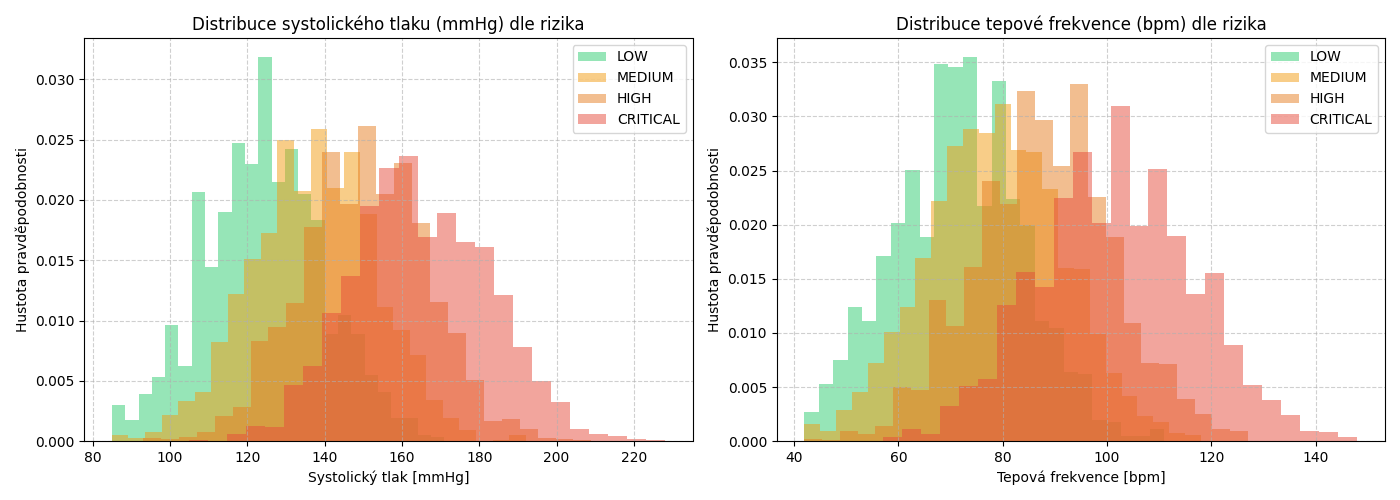

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
risk_order = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']
colors = {'LOW': '#2ecc71', 'MEDIUM': '#f39c12', 'HIGH': '#e67e22', 'CRITICAL': '#e74c3c'}

for risk in risk_order:
    pats_in_risk = set(df_patients[df_patients['risk_category'] == risk]['patient_id'])
    sub = df_readings[df_readings['patient_id'].isin(pats_in_risk)]
    axes[0].hist(sub['vitals.systolic_bp'], bins=25, alpha=0.5, label=risk, color=colors[risk], density=True)
    axes[1].hist(sub['vitals.heart_rate'], bins=25, alpha=0.5, label=risk, color=colors[risk], density=True)

axes[0].set_title('Distribuce systolického tlaku (mmHg) dle rizika')
axes[0].set_xlabel('Systolický tlak [mmHg]')
axes[0].set_ylabel('Hustota pravděpodobnosti')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].set_title('Distribuce tepové frekvence (bpm) dle rizika')
axes[1].set_xlabel('Tepová frekvence [bpm]')
axes[1].set_ylabel('Hustota pravděpodobnosti')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

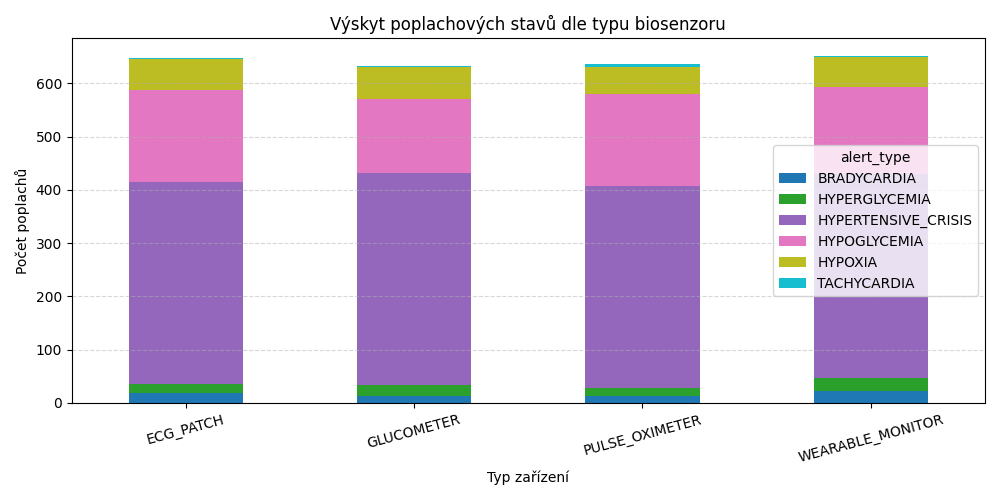

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
alert_counts = df_readings[df_readings['alert_triggered']].groupby(['device_type', 'alert_type']).size().unstack(fill_value=0)
alert_counts.plot(kind='bar', stacked=True, ax=ax, colormap='tab10')
ax.set_title('Výskyt poplachových stavů dle typu biosenzoru')
ax.set_xlabel('Typ zařízení')
ax.set_ylabel('Počet poplachů')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Závěry pro návrh schématu a shardingu v MongoDB

- **Kardinalita a distribuce klíče**: Pole `patient_id` obsahuje 500 unikátních hodnot, na které připadá 8 000 odečtů. Použitím hashovaného shard key `{ patient_id: "hashed" }` docílíme rovnoměrného rozložení chunků mezi 3 shardy (`shard1rs`, `shard2rs`, `shard3rs`), což zabrání vzniku zápisových horkých míst (hotspots).
- **Validace schématu ($jsonSchema)**: Rozsahy hodnot (např. tepová frekvence 30–240 bpm, SpO2 50–100 %, tlak 50–260 mmHg) a povinná pole zjištěná v této analýze jsou přímo zanesena do validačních pravidel kolekce.
- **Agregace a dotazy**: Vztah mezi pacienty, telemetrií a lékařskými intervencemi poskytuje bohatý základ pro netriviální agregační pipelines (`$lookup`, `$facet`, `$setWindowFields`, `$match`, detekce anomálií).